Dataset Loaded Successfully
   GDP per capita  Individuals using the Internet  Unemployment  \
1         556.302                           13.50         1.559   
2         547.228                           11.20         1.634   
3         578.466                            8.26         1.679   
4         613.856                            7.00         1.735   
5         637.165                            5.90         1.725   

   Life expectancy at birth  
1                    64.130  
2                    63.763  
3                    63.377  
4                    62.966  
5                    62.525  

SIMPLE LINEAR REGRESSION
Slope: 0.0011514401144837305
Intercept: 64.2218569710686
MSE: 66.05782461970337
RMSE: 8.127596484798158
R2 Score: 0.18013095126352718


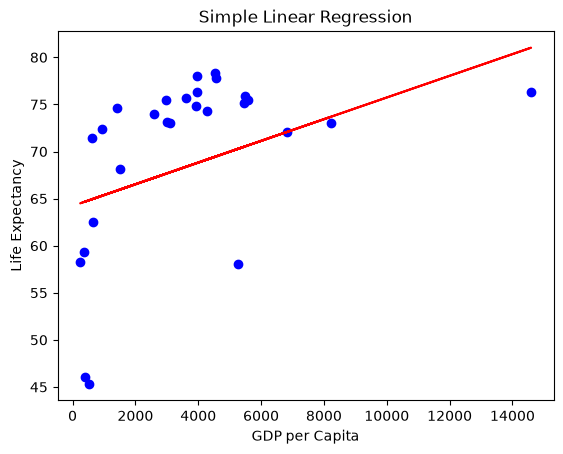


MULTIPLE LINEAR REGRESSION
Coefficients: [0.00061145 0.14924996 0.13490621]
Intercept: 62.14019239106248
MSE: 55.87663444488035
RMSE: 7.475067521091723
R2 Score: 0.30649361536414765


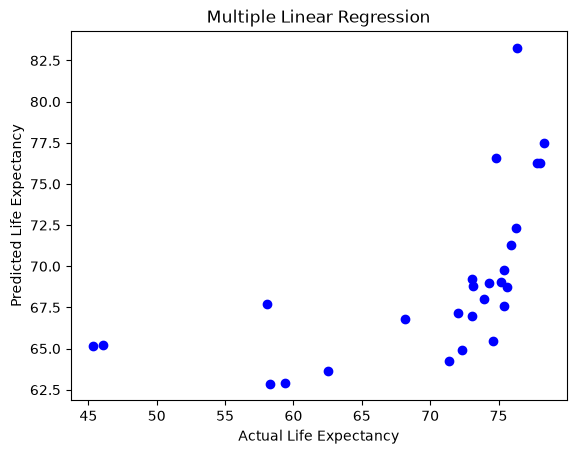

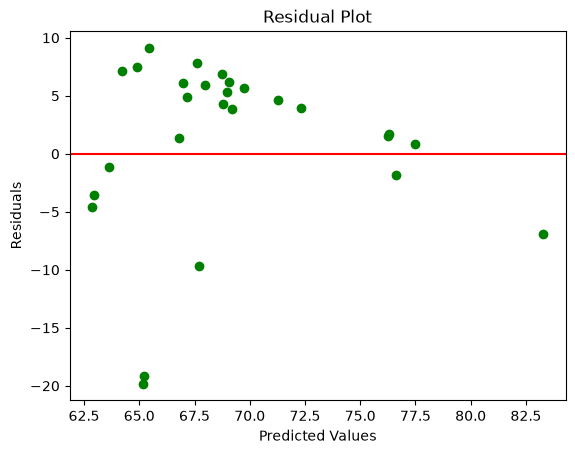


BOTH MODELS EXECUTED SUCCESSFULLY


In [8]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


# =====================================
# LOAD DATASET
# =====================================

df = pd.read_csv("World Economic Indicators - Sheet1.csv")

# Select required columns and remove missing values
df = df[['GDP per capita',
         'Individuals using the Internet',
         'Unemployment',
         'Life expectancy at birth']].dropna()

print("Dataset Loaded Successfully")
print(df.head())


# =====================================
# 1. SIMPLE LINEAR REGRESSION
# =====================================

print("\nSIMPLE LINEAR REGRESSION")

# Independent and dependent variables
X1 = df[['GDP per capita']]
y1 = df['Life expectancy at birth']

# Split data
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42
)

# Create and train model
model1 = LinearRegression()
model1.fit(X1_train, y1_train)

# Prediction
pred1 = model1.predict(X1_test)

# Evaluation
print("Slope:", model1.coef_[0])
print("Intercept:", model1.intercept_)
print("MSE:", mean_squared_error(y1_test, pred1))
print("RMSE:", mean_squared_error(y1_test, pred1) ** 0.5)
print("R2 Score:", r2_score(y1_test, pred1))

# Plot graph
plt.scatter(X1_test, y1_test, color='blue')
plt.plot(X1_test, pred1, color='red')
plt.xlabel("GDP per Capita")
plt.ylabel("Life Expectancy")
plt.title("Simple Linear Regression")
plt.show()


# =====================================
# 2. MULTIPLE LINEAR REGRESSION
# =====================================

print("\nMULTIPLE LINEAR REGRESSION")

# Independent and dependent variables
X2 = df[['GDP per capita',
         'Individuals using the Internet',
         'Unemployment']]

y2 = df['Life expectancy at birth']

# Split data
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

# Create and train model
model2 = LinearRegression()
model2.fit(X2_train, y2_train)

# Prediction
pred2 = model2.predict(X2_test)

# Evaluation
print("Coefficients:", model2.coef_)
print("Intercept:", model2.intercept_)
print("MSE:", mean_squared_error(y2_test, pred2))
print("RMSE:", mean_squared_error(y2_test, pred2) ** 0.5)
print("R2 Score:", r2_score(y2_test, pred2))

# Plot graph
plt.scatter(y2_test, pred2, color='blue')
plt.xlabel("Actual Life Expectancy")
plt.ylabel("Predicted Life Expectancy")
plt.title("Multiple Linear Regression")
plt.show()


# =====================================
# 3. CHECKING MODEL ASSUMPTIONS
# =====================================

residuals = y2_test - pred2

plt.scatter(pred2, residuals, color='green')
plt.axhline(y=0, color='red')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


# =====================================
# FINAL RESULT
# =====================================

print("\nBOTH MODELS EXECUTED SUCCESSFULLY")
